# Counting barnacles: DALI Data Challenge

**Goal:** count barnacles in tide-pool photos. I have two photos with hand-drawn labels (`img1`, `img2`) and two with none (`unseen_img1`, `unseen_img2`).

**Short version:** I turned the hand-drawn outlines into ground truth, wrote a scorer, and tried four detectors: brightness threshold, template matching, blob detection, and a random-forest patch classifier. The random forest was clearly the best. It got an F1 of about 0.7 on the right half of `img1` (random points get about 0.2) and about 0.55 on the right half of `img2` (random points about 0.18). The one test on a fully unseen labeled photo is a lot weaker, an F1 of about 0.4 on `img2`. So it works on photos it was trained on and only partly carries over to a new one. Bare rock, the wire frame and the ruler fool it. These numbers are rough: the labels are incomplete and my test splits aren't fully independent (caveats are at the end).

**AI use:** I used Claude on this project for debugging, checking my work, writing code, and rewording some of the explanations in this notebook. For example, it helped me catch that my first chance baseline was wrong. I ran everything myself, did the hand counts, and went through the code and results so I understand what each part does and why.

**To run:** put `img1.png`, `img2.png`, `mask1.png`, `mask2.png`, `unseen_img1.png` and `unseen_img2.png` in the same folder as this notebook, along with `barnacle_utils.py` (my helper functions). Then Restart and Run All. You need `opencv-python`, `numpy`, `matplotlib` and `scikit-learn` (see `requirements.txt`). The random-forest sections take a few minutes. Everything random is seeded, so a full run should reproduce the numbers below to about the second decimal, though library versions can move them a little.

**Contents**
1. Idea, subtasks, metrics
2. Loading the photos and masks
3. Turning the masks into ground truth
4. How I score a detector (and what chance looks like)
5. Attempt 1: brightness threshold
6. Attempt 2: template matching
7. Attempt 3: blob detection (difference of Gaussians)
8. Attempt 4: random-forest patch classifier
9. Running on the unseen photos
10. Results, caveats, conclusions, what I learned

## 1. Idea, subtasks, metrics

**Idea:** Counting by hand is slow because someone has to find every single barnacle. So I turned it into a detection problem: mark barnacle centers in the two labeled photos, train a model to recognize what a center looks like, and have it propose dots that a person can then count.

**Subtasks:** (1) turn the hand-drawn outlines into ground truth centers, (2) build a scorer, (3) build a detector, (4) check counts on photos with no labels, (5) deal with things that aren't barnacles, like the wire frame, the ruler and bare rock.

**The subtask I picked and how I measure it:** center detection. A detection counts as correct if it lands within 10 px of a labeled center on `img1` (18 px on `img2`, since its barnacles are bigger), and each label can only be matched once. I report precision, recall, F1 and count error, next to the F1 of random points as a chance level.

## 2. Loading the photos and masks

OpenCV loads images as NumPy arrays in **BGR** order and indexes them `[row, column]`, so y comes first. Matplotlib wants RGB, so I convert before plotting. The masks are blue outlines on a white background, and they're exactly the same size as the photos (2448 x 3264), so mask pixels line up with photo pixels and nothing needs aligning.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# helper functions (ground truth, scorer, detectors, frame detection) live in barnacle_utils.py
from barnacle_utils import (getBarnacleContours, getCenters, evaluate, f1, randomBaseline, describe,
                            nearestOffsets, findPeaks, getPatch, makeDataset, trainForest,
                            probabilityMap, detect, findInnerSquare, detectOnPhoto)

In [2]:
img1 = cv2.imread("img1.png")
maskImg1 = cv2.imread("mask1.png")
print("photo:", img1.shape, img1.dtype)
print("mask: ", maskImg1.shape, maskImg1.dtype)

photo: (2448, 3264, 3) uint8
mask:  (2448, 3264, 3) uint8


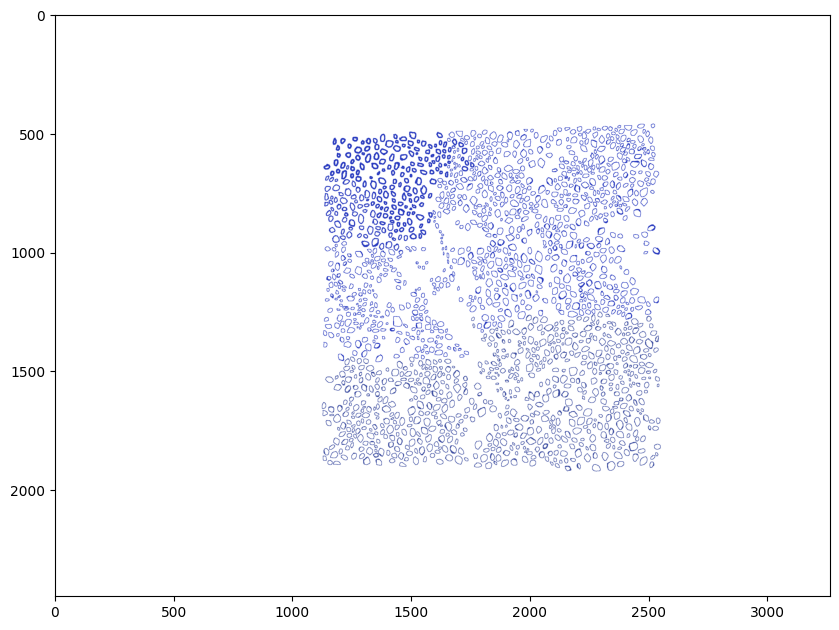

In [3]:
maskRgb = cv2.cvtColor(maskImg1, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10,8))
plt.imshow(maskRgb)
plt.show()

## 3. Turning the masks into ground truth

The outline pixels are blue (about `[191, 57, 39]` in BGR) and the background is white, so I call a pixel "line" when its red channel is below 200. Overlaying those pixels on the photo shows that each outline wraps the central opening of the barnacle, where the grey diamond of plates shows. It isn't the whole shell, and it isn't especially dark. Also, lots of barnacles in the crop below have no outline at all, so the labels are incomplete even in `img1`.

In [4]:
isLine = maskImg1[:, :, 2] < 200

overlay = img1.copy()
overlay[isLine] = (255, 255, 0)

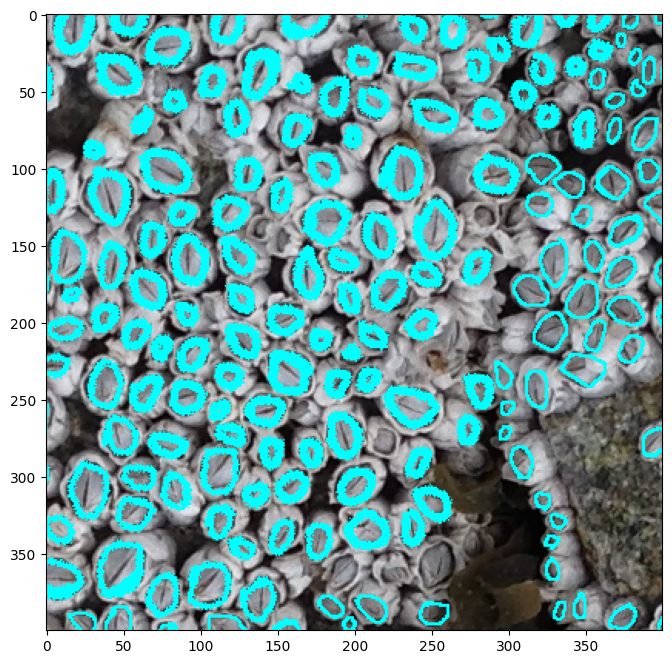

In [5]:
overlayRgb = cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10,8))
plt.imshow(overlayRgb[600:1000, 1300:1700])
plt.show()

Next I find the closed loops. `RETR_LIST` returns both the inner and outer edge of every drawn line, which roughly doubles the count (3850), so I use `RETR_EXTERNAL` (1740). That's still too many: some are zero-area specks, and some loops have tiny gaps, so one barnacle splits into pieces.

In [6]:
lineImg = isLine.astype(np.uint8) * 255
print(lineImg.shape)
print(lineImg.dtype)

(2448, 3264)
uint8


In [7]:
contoursList, _ = cv2.findContours(lineImg, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
contoursExt, _ = cv2.findContours(lineImg, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
print(len(contoursList), len(contoursExt))

3850 1740


smallest: 0.0
median: 309.5
largest: 1384.0
20 smallest: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


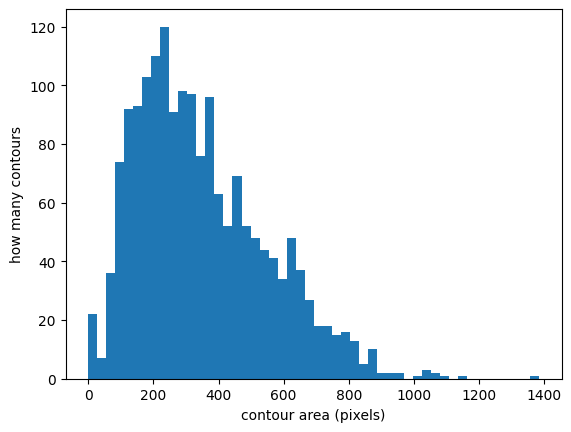

In [8]:
areas = [cv2.contourArea(c) for c in contoursExt]

print("smallest:", min(areas))
print("median:", np.median(areas))
print("largest:", max(areas))
print("20 smallest:", sorted(areas)[:20])

plt.hist(areas, bins=50)
plt.xlabel("contour area (pixels)")
plt.ylabel("how many contours")
plt.show()

In [9]:
for cutoff in [20, 50, 80, 100]:
    cleanContours = [c for c in contoursExt if cv2.contourArea(c) > cutoff]
    print(len(cleanContours))

1718
1712
1677
1635


Dropping small contours removes the specks (1740 down to about 1718), but the count keeps sliding as the cutoff grows, which means I'm cutting real small barnacles too. A better fix for the broken loops is a morphological closing (grow the lines a little, then shrink them back), which seals the gaps. With a cutoff of 30 pixels the count goes from 1718 before closing to 1500 after.

In [10]:
cutoff = 30

kernel = np.ones((3, 3), np.uint8)
closedImg = cv2.morphologyEx(lineImg, cv2.MORPH_CLOSE, kernel)

contoursClosed, _ = cv2.findContours(closedImg, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cleanClosed = [c for c in contoursClosed if cv2.contourArea(c) > cutoff]

print("before closing:", len([c for c in contoursExt if cv2.contourArea(c) > cutoff]))
print("after closing: ", len(cleanClosed))

before closing: 1718
after closing:  1500


I wrapped this into one function and ran it on both masks: 1500 barnacles in `img1` and 390 in `img2`. The barnacles in `img2` are much bigger (median outline area about 1092 px vs 362 px in `img1`, a scale of about 1.74), so one fixed window size won't suit both photos.

In [11]:
contours1 = getBarnacleContours("mask1.png")
contours2 = getBarnacleContours("mask2.png")
print(len(contours1), len(contours2))

1500 390


In [12]:
areas1 = [cv2.contourArea(c) for c in contours1]
areas2 = [cv2.contourArea(c) for c in contours2]

print("median img1:", np.median(areas1))
print("median img2:", np.median(areas2))

median img1: 362.25
median img2: 1091.5


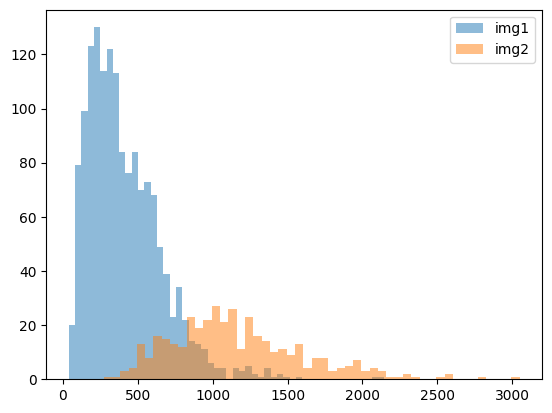

In [13]:
plt.hist(areas1, bins=50, alpha=0.5, label="img1")
plt.hist(areas2, bins=50, alpha=0.5, label="img2")
plt.legend()
plt.show()

Each barnacle's center is the centroid of its outline, computed from image moments. As a sanity check, the plot below puts those centers (red) on a crop of the photo.

In [14]:
centers1 = getCenters(contours1)
centers2 = getCenters(contours2)
print(centers1.shape, centers2.shape)

(1500, 2) (390, 2)


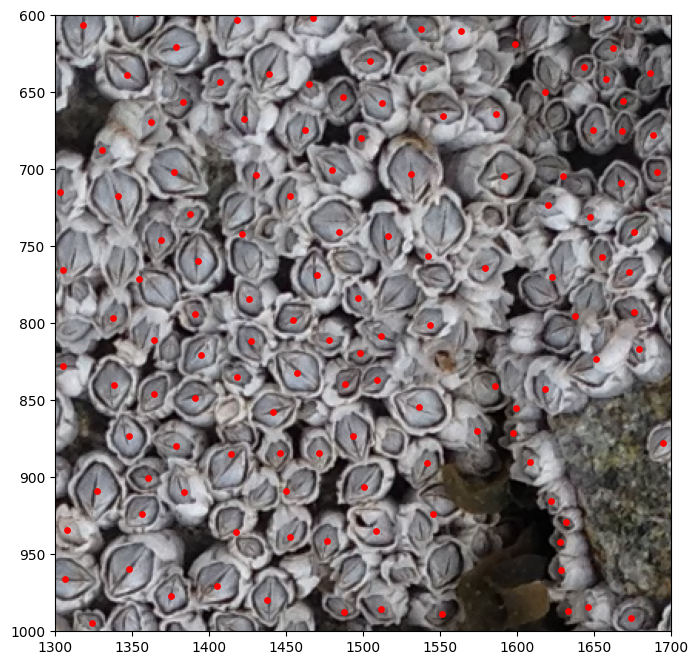

In [15]:
img1Rgb = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 8))
plt.imshow(img1Rgb)
plt.scatter(centers1[:, 0], centers1[:, 1], s=15, c="red")
plt.xlim(1300, 1700)     # x range: left to right
plt.ylim(1000, 600)      # y range: bigger number first, since row 0 is at the top
plt.show()

## 4. How I score a detector (and what chance looks like)

**`evaluate`** matches each detection to at most one labeled barnacle within `maxDist` pixels (closest pairs first) and reports precision, recall and the count error (detections minus real barnacles). I tried it on easy cases first: perfect input scores 1.0, and a little jitter still scores about 1.0.

**What does chance look like?** 
I got this wrong the first time. I scattered random points over a 1500 x 1500 square, but the labeled barnacles start at x of about 1130, so only about 17% of those points could ever land near a label, and I reported "chance is about 0.03". The fair version scatters the *same number of random points inside the labeled box* and scores them the same way. That gives an F1 of about **0.21** at `maxDist=10`, **0.40** at 15 and **0.55** at 20 (for 750 points). The barnacles are so crowded that a random point is within 20 px of one about half the time. So every score below is shown next to the chance F1 for the same number of detections, and a loose match distance doesn't tell you much.

To avoid leakage, anything that learns from the labels (a template, a classifier) only learns from the left half of `img1` (x < 1835) and is scored only on the right half. I also only count detections inside the bounding box of the labeled region, since there are barnacles nobody labeled outside it.

Some real barnacles have no outline, and a detection on one of them counts as a false positive. So precision is probably understated. Recall could be overstated if the labeled barnacles are the easier ones. I don't know what the net effect is.

In [16]:
print(evaluate(centers1, centers1))                                                       # perfect: both 1.0
print(evaluate(centers1 + np.random.default_rng(0).normal(0, 3, centers1.shape), centers1))   # small jitter: still about 1.0

{'predicted': 1500, 'true': 1500, 'count_error': 0, 'precision': 1.0, 'recall': 1.0}
{'predicted': 1500, 'true': 1500, 'count_error': 0, 'precision': 0.998, 'recall': 0.998}


In [17]:
# the labeled region of img1, and the left/right split used everywhere below
x0, y0 = centers1.min(axis=0)
x1, y1 = centers1.max(axis=0)
box1R = (1835, x1, y0, y1)                       # right half of the labeled region = test region
rightTrue = centers1[centers1[:, 0] >= 1835]
leftTrue1 = centers1[centers1[:, 0] < 1835]

def scoreRight(pred, maxDist=10):
    keep = ((pred[:, 0] >= 1835) & (pred[:, 0] <= x1) &
            (pred[:, 1] >= y0) & (pred[:, 1] <= y1))
    return evaluate(pred[keep], rightTrue, maxDist)

# chance level under exactly this protocol: 750 random points inside the right-half box
for md in (10, 15, 20):
    b = randomBaseline(rightTrue, box1R, 750, md)
    print(f"maxDist={md}: P={b['precision']:.2f} R={b['recall']:.2f} F1={b['F1']:.2f}")

maxDist=10: P=0.21 R=0.21 F1=0.21
maxDist=15: P=0.40 R=0.39 F1=0.40
maxDist=20: P=0.55 R=0.54 F1=0.55


## 5. Attempt 1: brightness threshold

The idea was that barnacle openings look darker than what's around them, so I threshold the grayscale image locally and count the blobs. (Looking at the outlines more closely later, the outlined area is the grey diamond of plates rather than a dark hole, so the premise was only partly right.)

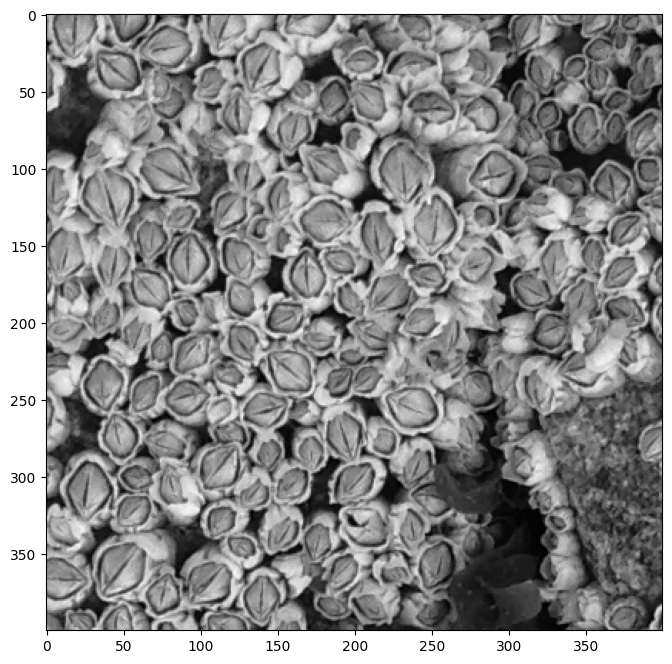

In [18]:
gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(8, 8))
plt.imshow(gray1[600:1000, 1300:1700], cmap="gray")
plt.show()

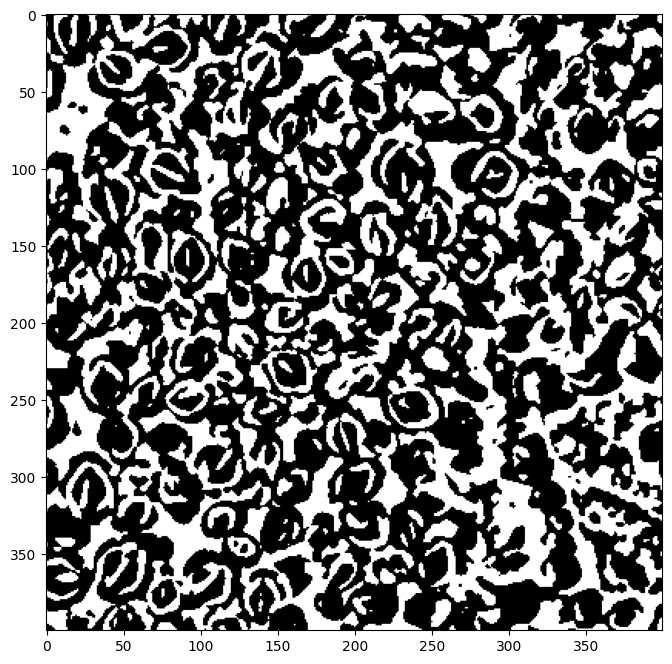

In [19]:
blur1 = cv2.GaussianBlur(gray1, (7, 7), 0)    # smooth out tiny texture

BLOCK = 51    # neighborhood size, must be odd
C = 5         # how much darker than the neighborhood counts

binary1 = cv2.adaptiveThreshold(blur1, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                cv2.THRESH_BINARY_INV, BLOCK, C)

plt.figure(figsize=(8, 8))
plt.imshow(binary1[600:1000, 1300:1700], cmap="gray")
plt.show()

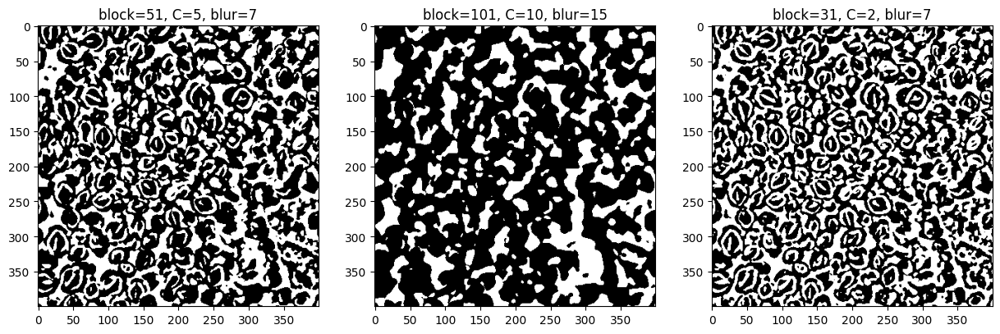

In [20]:
settings = [(51, 5, 7), (101, 10, 15), (31, 2, 7)]   # (BLOCK, C, blur size)

plt.figure(figsize=(15, 5))
for i, (block, c, k) in enumerate(settings):
    blurred = cv2.GaussianBlur(gray1, (k, k), 0)
    b = cv2.adaptiveThreshold(blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                              cv2.THRESH_BINARY_INV, block, c)
    plt.subplot(1, 3, i + 1)
    plt.imshow(b[600:1000, 1300:1700], cmap="gray")
    plt.title(f"block={block}, C={c}, blur={k}")
plt.show()

It failed. Dark rock, shadows and gaps between shells are just as dark as anything inside a barnacle, and no setting of the three parameters separated them.

## 6. Attempt 2: template matching

The idea was to average a lot of labeled barnacles (left half of `img1`) into one "typical barnacle" image, then slide it over the photo and look for strong matches.

736 (41, 41)


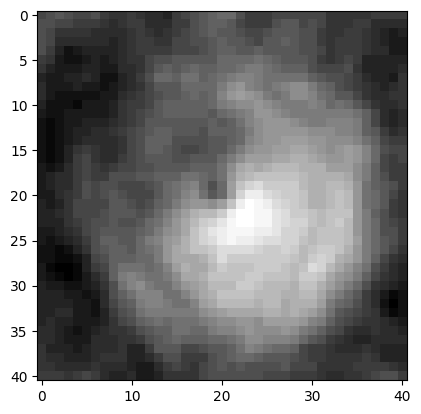

In [21]:
half = 20                                  # patch is (2*half + 1) = 41 pixels square

leftCenters = centers1[centers1[:, 0] < 1835]    # keep only barnacles with x < 1835 (left half)

patches = []
for cx, cy in leftCenters:
    x, y = int(round(cx)), int(round(cy))
    patch = gray1[y - half : y + half + 1, x - half : x + half + 1]   # note: rows (y) first
    if patch.shape == (2 * half + 1, 2 * half + 1):    # skip ones cut off by the image edge
        patches.append(patch.astype(np.float32))

template = np.mean(patches, axis=0).astype(np.uint8)
print(len(patches), template.shape)

plt.imshow(template, cmap="gray")
plt.show()

In [22]:
result = cv2.matchTemplate(gray1, template, cv2.TM_CCOEFF_NORMED)
# result[y, x] = how well the template matches with its top-left corner at (x, y)

thresh = 0.5       # how strong a match must be
minDist = 10       # peaks closer than this count as one
kernel = np.ones((2 * minDist + 1, 2 * minDist + 1), np.uint8)

# a peak = the highest value in its neighborhood AND above the threshold
localMax = (result == cv2.dilate(result, kernel)) & (result > thresh)
ys, xs = np.nonzero(localMax)
predCenters = np.column_stack([xs + half, ys + half])   # shift from top-left corner to patch center

# score only inside the labeled region, right half
keep = ((predCenters[:, 0] >= 1835) & (predCenters[:, 0] <= x1) &
        (predCenters[:, 1] >= y0) & (predCenters[:, 1] <= y1))
rightPred = predCenters[keep]

print(describe(evaluate(rightPred, rightTrue, maxDist=10), rightTrue, box1R, 10))

predicted=  78 (count -89.8%)  P=0.40 R=0.04 F1=0.07  chance F1=0.05


A match threshold of 0.5 was way too strict (78 detections vs 764 real). Here's a sweep:

In [23]:
for thresh in [0.1, 0.2, 0.3, 0.4, 0.5]:
    localMax = (result == cv2.dilate(result, kernel)) & (result > thresh)
    ys, xs = np.nonzero(localMax)
    predCenters = np.column_stack([xs + half, ys + half])

    keep = ((predCenters[:, 0] >= 1835) & (predCenters[:, 0] <= x1) &
            (predCenters[:, 1] >= y0) & (predCenters[:, 1] <= y1))
    s = evaluate(predCenters[keep], rightTrue, maxDist=10)
    print(f"thresh={thresh}  " + describe(s, rightTrue, box1R, 10))

thresh=0.1  predicted= 715 (count  -6.4%)  P=0.44 R=0.41 F1=0.43  chance F1=0.20
thresh=0.2  predicted= 644 (count -15.7%)  P=0.44 R=0.37 F1=0.40  chance F1=0.19
thresh=0.3  predicted= 442 (count -42.1%)  P=0.42 R=0.24 F1=0.31  chance F1=0.16
thresh=0.4  predicted= 231 (count -69.8%)  P=0.44 R=0.13 F1=0.21  chance F1=0.10
thresh=0.5  predicted=  78 (count -89.8%)  P=0.40 R=0.04 F1=0.07  chance F1=0.05


The best F1 is 0.43 at a threshold of 0.1, about double chance (0.20), and the count is about 6% low. Precision stays near 0.44 (chance is about 0.21) whatever the threshold, which suggests a lot of detections land on a barnacle but not close enough to its center. Here's how much the match distance matters:

In [24]:
thresh = 0.1
localMax = (result == cv2.dilate(result, kernel)) & (result > thresh)
ys, xs = np.nonzero(localMax)
predCenters = np.column_stack([xs + half, ys + half])
keep = ((predCenters[:, 0] >= 1835) & (predCenters[:, 0] <= x1) &
        (predCenters[:, 1] >= y0) & (predCenters[:, 1] <= y1))

for md in [10, 15, 20]:
    s = evaluate(predCenters[keep], rightTrue, maxDist=md)
    print(f"maxDist={md}  " + describe(s, rightTrue, box1R, md))

maxDist=10  predicted= 715 (count  -6.4%)  P=0.44 R=0.41 F1=0.43  chance F1=0.20
maxDist=15  predicted= 715 (count  -6.4%)  P=0.66 R=0.62 F1=0.64  chance F1=0.39
maxDist=20  predicted= 715 (count  -6.4%)  P=0.77 R=0.72 F1=0.74  chance F1=0.54


A looser tolerance raises the template score (F1 0.43, 0.64, 0.74 at 10, 15 and 20 px), but it raises the score of random points almost as fast (0.20, 0.39, 0.54). The lead over chance shrinks from about 2.2x to about 1.4x, so the 20 px number says very little and I treat 10 px as the only meaningful setting. Template matching does find barnacle-rich places, but it's imprecise about the center. I tested whether the error was a consistent shift:

In [25]:
# left-half detections and truth
leftKeep = ((predCenters[:, 0] < 1835) & (predCenters[:, 0] >= x0) &
            (predCenters[:, 1] >= y0) & (predCenters[:, 1] <= y1))
leftPred = predCenters[leftKeep]
leftTrue = centers1[centers1[:, 0] < 1835]

off = nearestOffsets(leftPred, leftTrue)
print("mean offset:", off.mean(axis=0), " spread:", off.std(axis=0))

# apply the correction to the right half and re-score at the original strict distance
rightPred = predCenters[keep]
shift = off.mean(axis=0)
print(evaluate(rightPred + shift, rightTrue, maxDist=10))

mean offset: [ 0.64136674 -0.36138038]  spread: [7.86622488 8.81947067]
{'predicted': 715, 'true': 764, 'count_error': -49, 'precision': 0.44475524475524475, 'recall': 0.4162303664921466}


No. The average offset is about 0 px but the spread is about 8-9 px, so the error is random scatter, not a consistent shift, and a correction can't fix it.

To compare methods, I score everything at 10 px (18 px on `img2`, whose barnacles are bigger), with each score shown next to the chance F1 for the same number of detections.

## 7. Attempt 3: blob detection (difference of Gaussians)

The idea behind this was to subtract a heavily blurred copy of the photo from a lightly blurred one, so blob-shaped things of a chosen size stand out, then take the peaks.

The peak finder `findPeaks(response, thresh, minDist)` is in `barnacle_utils.py`. A spot counts as a peak if it's the highest value in its neighborhood and above `thresh`. The template-matching section did the same thing inline.

In [26]:
g = gray1.astype(np.float32)

for sigma in [4, 6, 8, 10]:
    dog = cv2.GaussianBlur(g, (0, 0), sigma) - cv2.GaussianBlur(g, (0, 0), sigma * 1.6)
    dog = (dog - dog.mean()) / dog.std()             # rescale so thresh means "std devs above average"
    for sign in [1, -1]:                             # +1: bright blobs, -1: dark blobs
        s = scoreRight(findPeaks(sign * dog, thresh=1.0))
        print(f"sigma={sigma} sign={sign:+d}  " + describe(s, rightTrue, box1R, 10))

sigma=4 sign=+1  predicted=1389 (count +81.8%)  P=0.18 R=0.32 F1=0.23  chance F1=0.25
sigma=4 sign=-1  predicted=1212 (count +58.6%)  P=0.12 R=0.18 F1=0.14  chance F1=0.24
sigma=6 sign=+1  predicted= 800 (count  +4.7%)  P=0.23 R=0.24 F1=0.24  chance F1=0.21
sigma=6 sign=-1  predicted= 707 (count  -7.5%)  P=0.07 R=0.07 F1=0.07  chance F1=0.20
sigma=8 sign=+1  predicted= 508 (count -33.5%)  P=0.32 R=0.21 F1=0.26  chance F1=0.17
sigma=8 sign=-1  predicted= 441 (count -42.3%)  P=0.05 R=0.03 F1=0.03  chance F1=0.16
sigma=10 sign=+1  predicted= 368 (count -51.8%)  P=0.37 R=0.18 F1=0.24  chance F1=0.14
sigma=10 sign=-1  predicted= 294 (count -61.5%)  P=0.06 R=0.02 F1=0.03  chance F1=0.13


The results were poor. The best F1 is 0.26 (sigma 8, bright blobs), against a chance F1 of 0.17 for that many detections. At sigma 4 and 6 the scores (0.23 and 0.24) are no better than chance (0.25 and 0.21), and the dark-blob versions are *below* chance (0.03 to 0.14). Bright blobs beating dark blobs fits with the grey diamond of plates being brighter than the gaps between barnacles, but that's a guess and I didn't test it. Also notice that sigma 6 gets the *count* about right (800 vs 764, +4.7%) with chance-level F1, so a correct total can hide detections in the wrong places.

## 8. Attempt 4: random-forest patch classifier

The idea is to let the computer learn what a barnacle center looks like. I cut a small square patch around each labeled center (positive) and around random spots away from any center (negative), shrink each patch to 21 x 21, normalize its brightness, and train a random forest to say "barnacle center or not". To detect, I score a grid of spots across the photo, smooth the probability map, and take the peaks above a threshold.

Every random choice uses a seed passed into the function, and each classifier is returned by `trainForest` and passed to `probabilityMap` explicitly, so re-running a cell gives the same answer.

The building blocks for this section are in `barnacle_utils.py`: `getPatch` (cuts out and normalizes a patch), `makeDataset` (positive and negative patches), `trainForest`, `probabilityMap` (scores a grid of spots) and `detect` (peaks of the probability map). The cells below use them and score the results.

`img2` has much bigger barnacles (about 1.74x wider, which is the square root of the ratio of median areas from Section 3), so its patch window is proportionally bigger too: `half2 = 35`, a 71 px square instead of 41 px. Setting up `img2` and its left/right split:

In [27]:
img2 = cv2.imread("img2.png")
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)
a0, b0 = centers2.min(axis=0)
a1, b1 = centers2.max(axis=0)
mid2 = (a0 + a1) / 2                                # split img2 down the middle too

box1L = (x0, 1835, y0, y1)                          # training region, img1
box2 = (a0, a1, b0, b1)                             # whole labeled region, img2
box2L = (a0, mid2, b0, b1)
box2R = (mid2, a1, b0, b1)
leftTrue2 = centers2[centers2[:, 0] < mid2]
rightTrue2 = centers2[centers2[:, 0] >= mid2]

scale = np.sqrt(np.median(areas2) / np.median(areas1))     # about 1.74
half2 = int(round(20 * scale))
print("scale:", scale, " half2:", half2)
print("labeled barnacles, left/right:  img1", len(leftTrue1), len(rightTrue), "  img2", len(leftTrue2), len(rightTrue2))

def scoreRight2(pred, maxDist=18):
    keep = ((pred[:, 0] >= mid2) & (pred[:, 0] <= a1) & (pred[:, 1] >= b0) & (pred[:, 1] <= b1))
    return evaluate(pred[keep], rightTrue2, maxDist)

def scoreBoth(clf, thresholds):
    """right half of img1 (10 px) and right half of img2 (18 px)"""
    pm1, xg1, yg1 = probabilityMap(clf, gray1, 1835, x1, y0, y1, half=20, stride=3)
    pm2, xg2, yg2 = probabilityMap(clf, gray2, mid2, a1, b0, b1, half=half2, stride=5)
    for t in thresholds:
        s1 = scoreRight(detect(pm1, xg1, yg1, t))
        s2 = scoreRight2(detect(pm2, xg2, yg2, t))
        print(f"thresh={t}")
        print("   img1: " + describe(s1, rightTrue, box1R, 10))
        print("   img2: " + describe(s2, rightTrue2, box2R, 18))

scale: 1.7358319306238612  half2: 35
labeled barnacles, left/right:  img1 736 764   img2 160 230


**8a. Trained on the left half of `img1` only.**

In [28]:
clfA = trainForest([(gray1, leftTrue1, centers1, box1L, 20, 3000)], seed=0)

# held-out patch accuracy, right half of img1
Xtest, ytest = makeDataset(gray1, rightTrue, centers1, box1R, 20, 1000, np.random.default_rng(1))
print("test patches:", Xtest.shape)
print("held-out accuracy:", clfA.score(Xtest, ytest))
print("always-guess-'not barnacle' accuracy:", (ytest == 0).mean())

pm1, xg1, yg1 = probabilityMap(clfA, gray1, 1835, x1, y0, y1, half=20, stride=3)
for thresh in [0.1, 0.2, 0.3, 0.4]:
    print(f"img1 right half  thresh={thresh}  " + describe(scoreRight(detect(pm1, xg1, yg1, thresh)), rightTrue, box1R, 10))

# img2 was never seen by this classifier, so score its whole labeled region
pm2full, xg2f, yg2f = probabilityMap(clfA, gray2, a0, a1, b0, b1, half=half2, stride=5)
for thresh in [0.1, 0.2, 0.3]:
    s = evaluate(detect(pm2full, xg2f, yg2f, thresh), centers2, 18)
    print(f"img2 whole photo thresh={thresh}  " + describe(s, centers2, box2, 18))

test patches: (1764, 441)
held-out accuracy: 0.7443310657596371
always-guess-'not barnacle' accuracy: 0.5668934240362812
img1 right half  thresh=0.1  predicted= 750 (count  -1.8%)  P=0.75 R=0.73 F1=0.74  chance F1=0.21
img1 right half  thresh=0.2  predicted= 734 (count  -3.9%)  P=0.76 R=0.73 F1=0.75  chance F1=0.20
img1 right half  thresh=0.3  predicted= 653 (count -14.5%)  P=0.80 R=0.68 F1=0.74  chance F1=0.20
img1 right half  thresh=0.4  predicted= 309 (count -59.6%)  P=0.86 R=0.35 F1=0.49  chance F1=0.13
img2 whole photo thresh=0.1  predicted= 644 (count +65.1%)  P=0.30 R=0.50 F1=0.38  chance F1=0.17
img2 whole photo thresh=0.2  predicted= 423 (count  +8.5%)  P=0.31 R=0.34 F1=0.32  chance F1=0.14
img2 whole photo thresh=0.3  predicted=  59 (count -84.9%)  P=0.10 R=0.02 F1=0.03  chance F1=0.04


Held-out patch accuracy is 0.74, against 0.57 for always guessing "not a barnacle". On the right half of `img1`, F1 is about **0.74-0.75** at thresholds from 0.1 to 0.3 (chance about 0.2), and the count is within 2-4% at the lower thresholds. That's far above the earlier methods. On `img2`, a photo this classifier has never seen, the best F1 is **0.38** (chance 0.17) and it **overcounts by about 65%**. The overlay below shows where the extra detections are.

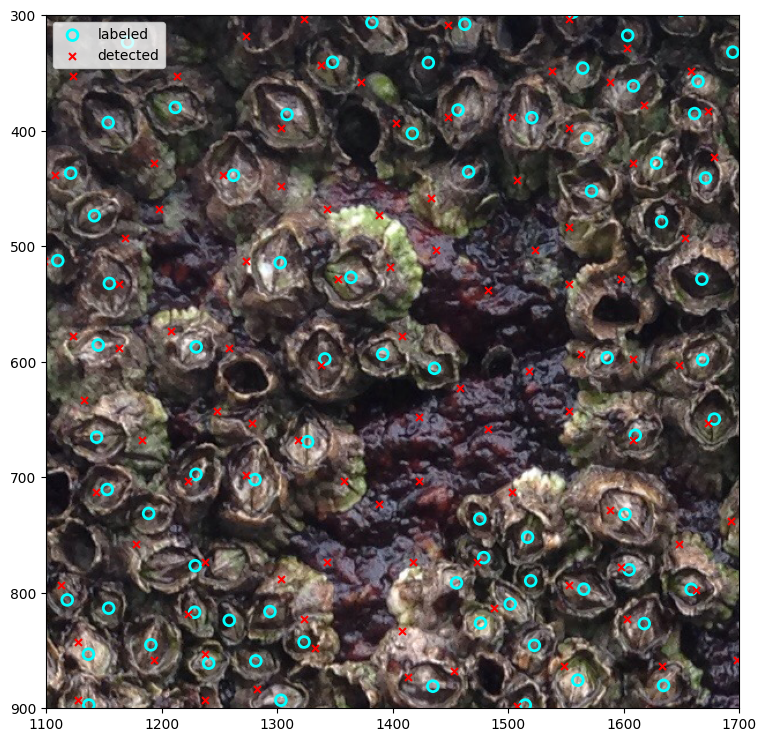

In [29]:
pred2 = detect(pm2full, xg2f, yg2f, 0.1)
img2Rgb = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(9, 9))
plt.imshow(img2Rgb)
plt.scatter(centers2[:, 0], centers2[:, 1], s=60, facecolors="none",
            edgecolors="cyan", linewidths=2, label="labeled")
plt.scatter(pred2[:, 0], pred2[:, 1], s=25, c="red", marker="x", label="detected")
plt.xlim(1100, 1700)
plt.ylim(900, 300)
plt.legend()
plt.show()

The overlay shows false detections on bare dark rock and shell rims, centers scattered off the middle of barnacles, and some barnacles that just have no label (so some "false positives" may be real; I look at that more closely below).

**8b. Trained on the left halves of both photos.** 
To help it handle both sizes, I train on `img1` (window 20) and `img2` (window 35) together and test on the right half of each. Note that `img2` is now a same-photo split, which is an easier test than a truly unseen photo.

In [30]:
partsB = [(gray1, leftTrue1, centers1, box1L, 20, 3000),
          (gray2, leftTrue2, centers2, box2L, half2, 3000)]
clfB = trainForest(partsB, seed=0)
scoreBoth(clfB, [0.1, 0.2, 0.3, 0.4])

thresh=0.1
   img1: predicted= 688 (count  -9.9%)  P=0.70 R=0.63 F1=0.66  chance F1=0.20
   img2: predicted= 270 (count +17.4%)  P=0.50 R=0.59 F1=0.54  chance F1=0.18
thresh=0.2
   img1: predicted= 666 (count -12.8%)  P=0.72 R=0.63 F1=0.67  chance F1=0.19
   img2: predicted= 121 (count -47.4%)  P=0.50 R=0.27 F1=0.35  chance F1=0.11
thresh=0.3
   img1: predicted= 558 (count -27.0%)  P=0.76 R=0.56 F1=0.64  chance F1=0.19
   img2: predicted=  11 (count -95.2%)  P=0.09 R=0.00 F1=0.01  chance F1=0.01
thresh=0.4
   img1: predicted= 157 (count -79.5%)  P=0.87 R=0.18 F1=0.30  chance F1=0.08
   img2: predicted=   0 (count -100.0%)  P=0.00 R=0.00 F1=0.00  chance F1=0.00


`img2` improves (0.38 to about 0.54 at threshold 0.1), though that isn't a like-for-like comparison: the 0.38 is a fully unseen photo and the 0.54 is a same-photo split. `img1` gets worse (about 0.75 to 0.66-0.67), and `img2`'s probabilities are much lower overall (its F1 is 0.35 at 0.2 and about 0 at 0.3 and above). I also did something I didn't intend: I gave each photo 3000 negative patches, but only 160 `img2` barnacles are in the training half (736 for `img1`), so `img2` trained with about 19 negatives per positive against about 4 for `img1`. The next run balances that, with 4 negatives per positive in each photo.

**8c. Balanced negatives.**

In [31]:
partsC = [(gray1, leftTrue1, centers1, box1L, 20, 4 * len(leftTrue1)),
          (gray2, leftTrue2, centers2, box2L, half2, 4 * len(leftTrue2))]
clfC = trainForest(partsC, seed=0)
scoreBoth(clfC, [0.1, 0.2, 0.3, 0.4, 0.5])

thresh=0.1
   img1: predicted= 749 (count  -2.0%)  P=0.71 R=0.70 F1=0.71  chance F1=0.21
   img2: predicted= 314 (count +36.5%)  P=0.48 R=0.66 F1=0.56  chance F1=0.18
thresh=0.2
   img1: predicted= 738 (count  -3.4%)  P=0.72 R=0.70 F1=0.71  chance F1=0.20
   img2: predicted= 293 (count +27.4%)  P=0.50 R=0.64 F1=0.56  chance F1=0.18
thresh=0.3
   img1: predicted= 678 (count -11.3%)  P=0.76 R=0.68 F1=0.72  chance F1=0.20
   img2: predicted= 118 (count -48.7%)  P=0.52 R=0.27 F1=0.35  chance F1=0.12
thresh=0.4
   img1: predicted= 315 (count -58.8%)  P=0.85 R=0.35 F1=0.50  chance F1=0.13
   img2: predicted=   3 (count -98.7%)  P=0.33 R=0.00 F1=0.01  chance F1=0.00
thresh=0.5
   img1: predicted=  29 (count -96.2%)  P=0.93 R=0.04 F1=0.07  chance F1=0.02
   img2: predicted=   0 (count -100.0%)  P=0.00 R=0.00 F1=0.00  chance F1=0.00


Balancing helped `img1` (F1 about 0.71 at threshold 0.2, up from 0.67), and a single threshold of 0.2 now works for both photos. `img2` is about 0.56 at 0.2 but drops to 0.35 at 0.3 and to about 0 at 0.4, so the classifier is really less sure about `img2`'s barnacles. I didn't test why; having fewer `img2` training examples is one guess. The `img2` count is 27% too high at 0.2.

To figure out how much of that is just random-seed noise, I retrained with five different seeds:

In [32]:
f1img1, f1img2 = [], []
for seed in range(5):
    clf = trainForest(partsC, seed=seed)
    pm1, xg1, yg1 = probabilityMap(clf, gray1, 1835, x1, y0, y1, half=20, stride=3)
    pm2, xg2, yg2 = probabilityMap(clf, gray2, mid2, a1, b0, b1, half=half2, stride=5)
    f1img1.append(f1(scoreRight(detect(pm1, xg1, yg1, 0.2))))
    f1img2.append(f1(scoreRight2(detect(pm2, xg2, yg2, 0.2))))
    print(f"seed {seed}: img1 F1={f1img1[-1]:.3f}  img2 F1={f1img2[-1]:.3f}")
print(f"threshold 0.2, mean +- std over 5 seeds:  img1 {np.mean(f1img1):.3f} +- {np.std(f1img1):.3f}   "
      f"img2 {np.mean(f1img2):.3f} +- {np.std(f1img2):.3f}")

seed 0: img1 F1=0.711  img2 F1=0.562
seed 1: img1 F1=0.731  img2 F1=0.571
seed 2: img1 F1=0.736  img2 F1=0.540
seed 3: img1 F1=0.725  img2 F1=0.543
seed 4: img1 F1=0.728  img2 F1=0.564
threshold 0.2, mean +- std over 5 seeds:  img1 0.726 +- 0.008   img2 0.556 +- 0.012


The seed-to-seed spread is about 0.01 on both photos (0.008 on `img1` and 0.012 on `img2` in the run shown), so differences smaller than about 0.02 between runs or thresholds don't mean anything. Over five seeds, F1 at 0.2 is about 0.73 on `img1` and 0.555 on `img2`.

Looking at the "false positives" on `img2`. The labels are incomplete, and I wanted to know whether the extra detections are mostly real but unlabeled barnacles, or mostly empty shells with dark holes (which you could argue are correct exclusions). The cell below shows 30 randomly chosen detections that are more than 40 px from any labeled barnacle (red cross = detection, cyan rings = labeled barnacles).

detections: 293  matched: 147  unmatched: 146
unmatched within 18-40 px of a label: 52   more than 40 px from any label: 94


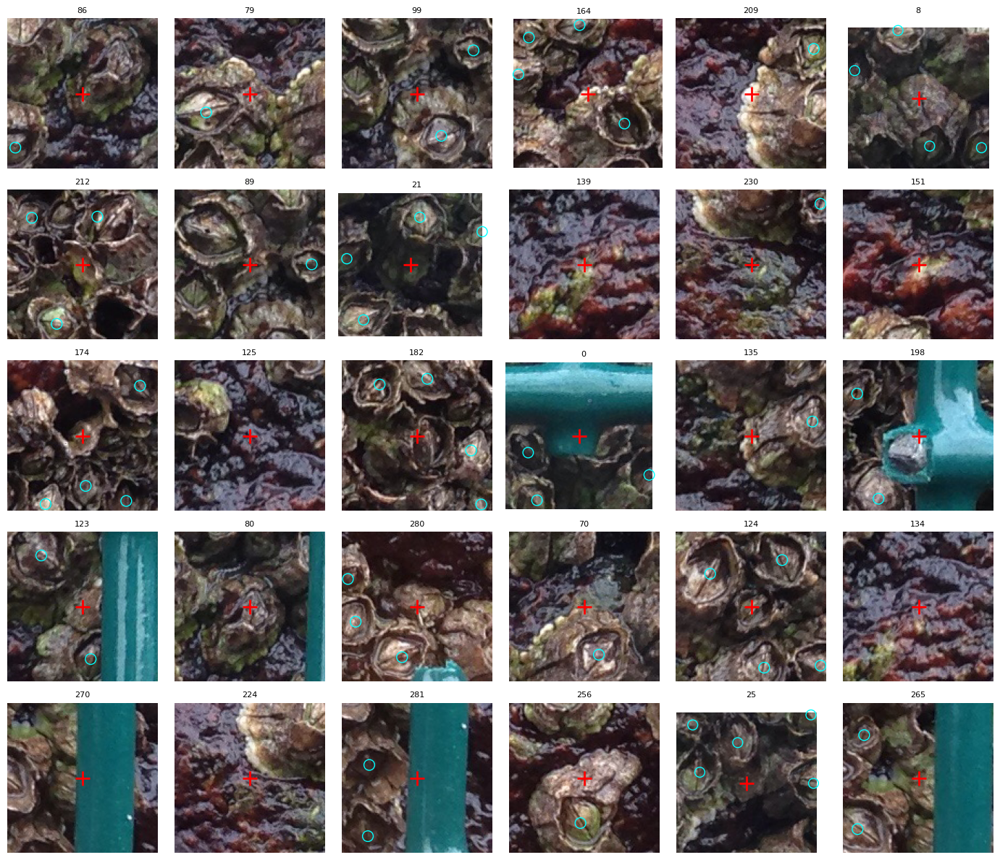

In [33]:
pm2c, xg2c, yg2c = probabilityMap(clfC, gray2, mid2, a1, b0, b1, half=half2, stride=5)
predC = detect(pm2c, xg2c, yg2c, 0.2)
predC = predC[(predC[:, 0] >= mid2) & (predC[:, 0] <= a1) & (predC[:, 1] >= b0) & (predC[:, 1] <= b1)]

# same greedy matching as evaluate(), but keep track of which detections matched
d = np.linalg.norm(predC[:, None, :] - rightTrue2[None, :, :], axis=2)
pairs = np.argwhere(d <= 18)
pairs = pairs[np.argsort(d[pairs[:, 0], pairs[:, 1]])]
usedP, usedT, matched = set(), set(), set()
for p, t in pairs:
    if p not in usedP and t not in usedT:
        usedP.add(p); usedT.add(t); matched.add(p)
unmatched = np.array([i for i in range(len(predC)) if i not in matched])
nearest = d[unmatched].min(axis=1)
print("detections:", len(predC), " matched:", len(matched), " unmatched:", len(unmatched))
print("unmatched within 18-40 px of a label:", int(((nearest > 18) & (nearest <= 40)).sum()),
      "  more than 40 px from any label:", int((nearest > 40).sum()))

far = unmatched[nearest > 40]
sample = np.random.default_rng(7).choice(far, size=min(30, len(far)), replace=False)

R = 70
padded = cv2.copyMakeBorder(img2, R, R, R, R, cv2.BORDER_CONSTANT, value=(0, 0, 0))
fig, axes = plt.subplots(5, 6, figsize=(14, 12))
for ax, i in zip(axes.ravel(), sample):
    x, y = int(round(predC[i, 0])), int(round(predC[i, 1]))
    ax.imshow(cv2.cvtColor(padded[y:y + 2 * R, x:x + 2 * R], cv2.COLOR_BGR2RGB))
    for lx, ly in rightTrue2:
        if abs(lx - x) < R and abs(ly - y) < R:
            ax.add_patch(plt.Circle((lx - x + R, ly - y + R), 5, fill=False, color="cyan"))
    ax.plot(R, R, "r+", markersize=14, mew=2)
    ax.set_title(str(i), fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

This is my reading of one run's 30 tiles (look at yours; it's a judgment call, the sample is small and my tallies are rough). About 8 are on bare rock, about 5 are directly on the wire frame (2 more sit against its edge), about 3 are on an empty shell or dark gap, and about 11 look like a real barnacle with no label, some partly covered in algae. So the idea that the unlabeled detections are mostly empty shells doesn't hold. Roughly a third of the far-from-label detections look like real, unlabeled barnacles, and the rest are rock, wire and a few empty shells. The other 52 unmatched detections lie 18-40 px from a labeled barnacle, mostly on the same barnacle's rim or its neighbor, which is off-center scatter.

One more thing: `img2` itself has the wire frame and bare rock in it, inside the labeled box too, so these aren't things the classifier never saw.

## 9. Running on the unseen photos

There are no labels for these, so I can't compute precision or recall. Instead I count detections, look at the overlays, and check the count by hand on a few crops. I use the final classifier from 8c (`clfC`) with a threshold of 0.2.

What to count: The challenge says scientists only count barnacles inside the inner square of the frame, so on `unseen_img1` I crop to that square instead of counting the whole photo. (`unseen_img2` is a close-up with no frame, so I use the whole image.)

**`unseen_img1`** has a wire frame with an orange ruler below it. The inner square has no wire inside it, so cropping to it also gets rid of the wire and the ruler, and I don't need a colour filter. `findInnerSquare` finds the four wire bars by colour (on a quarter-size copy of the photo) and returns the square between them, inset by a margin. I check the box by eye before using it.

inner square (xmin, xmax, ymin, ymax): [1066, 2510, 254, 1710]


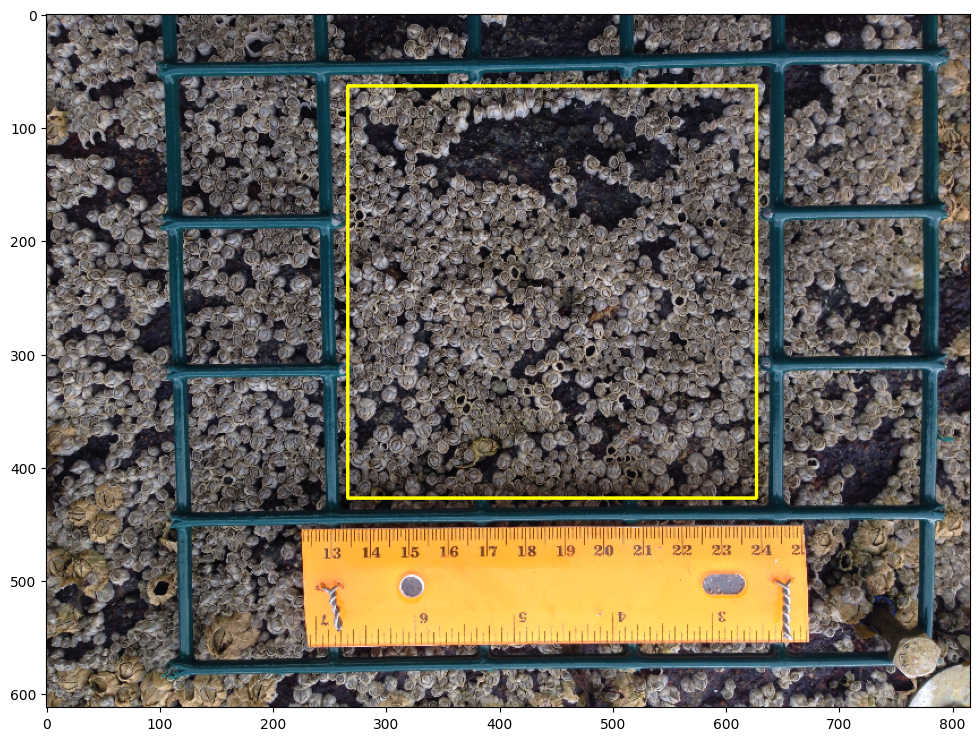

In [34]:
img = cv2.imread("unseen_img1.png")
innerBox = findInnerSquare(img)
print("inner square (xmin, xmax, ymin, ymax):", [round(v) for v in innerBox])

small = cv2.resize(img, None, fx=0.25, fy=0.25)
x_a, x_b, y_a, y_b = [int(v / 4) for v in innerBox]
cv2.rectangle(small, (x_a, y_a), (x_b, y_b), (0, 255, 255), 2)
plt.figure(figsize=(12, 9))
plt.imshow(cv2.cvtColor(small, cv2.COLOR_BGR2RGB))
plt.show()

Check the yellow box: It should sit inside the central square, clear of all four bars and well above the ruler. If it doesn't, set `innerBox` by hand from the picture (the axes are at quarter scale) before running the next cell.

unseen_img1, inside the inner square: 990


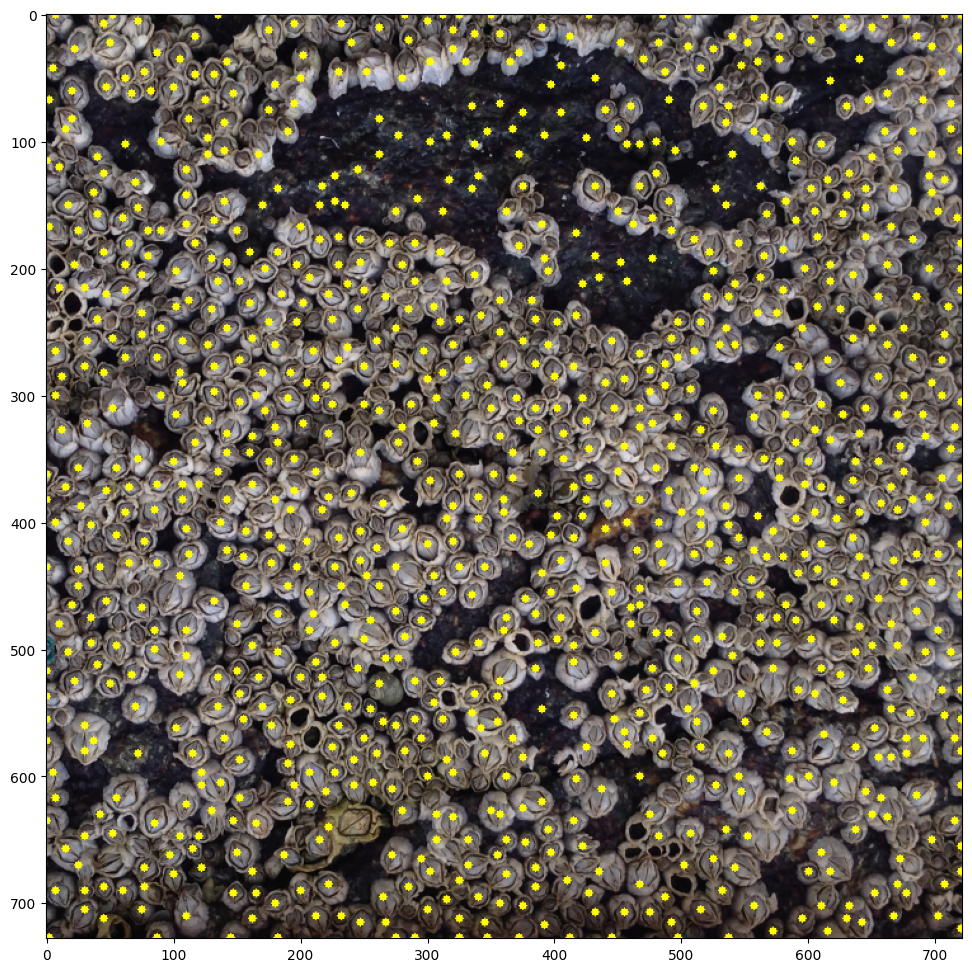

In [35]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
pts = detectOnPhoto(clfC, gray, half=20, stride=5, thresh=0.2, box=innerBox)
print("unseen_img1, inside the inner square:", len(pts))

x_a, x_b, y_a, y_b = [int(v) for v in innerBox]
crop = img[y_a:y_b, x_a:x_b]
small = cv2.resize(crop, None, fx=0.5, fy=0.5)
for x, y in pts:
    cv2.circle(small, (int((x - x_a) / 2), int((y - y_a) / 2)), 3, (0, 255, 255), -1)
plt.figure(figsize=(12, 12))
plt.imshow(cv2.cvtColor(small, cv2.COLOR_BGR2RGB))
plt.savefig("unseen1_overlay.png", dpi=150, bbox_inches="tight")
plt.show()

Hand-count check: To see how far I can trust the count, I counted the barnacles in a few random 200 x 200 crops by eye and compared with the detector. I count first, with no dots showing. The rule is that a barnacle counts if its center is inside the crop. The five crop positions are seeded so I'm not cherry-picking. Looking at the overlay above, a patch of bare dark rock in the upper-middle area has a few dozen dots that are probably false, and five random crops could easily miss it. So there's an optional sixth crop, `rockCorner`, that I placed by hand over that rock. I report it separately because I chose it on purpose.

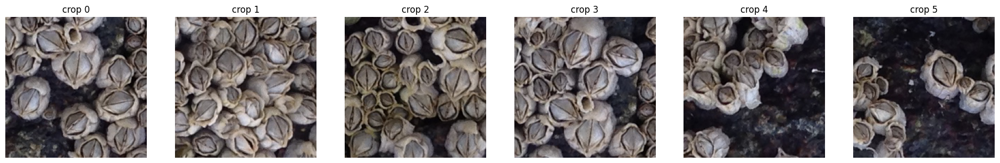

In [36]:
size, nCrops = 200, 5
rng = np.random.default_rng(42)
corners = [(int(rng.integers(x_a, x_b - size)), int(rng.integers(y_a, y_b - size))) for _ in range(nCrops)]

rockCorner = (1800, 450)   # top-left corner (x, y) of a 200 x 200 crop I placed by hand over bare dark rock
if rockCorner is not None:
    corners.append(rockCorner)
nCrops = len(corners)

fig, axes = plt.subplots(1, nCrops, figsize=(4 * nCrops, 4))
for k, (ax, (cx, cy)) in enumerate(zip(axes, corners)):
    ax.imshow(cv2.cvtColor(img[cy:cy + size, cx:cx + size], cv2.COLOR_BGR2RGB))
    ax.set_title(f"crop {k}")
    ax.axis("off")
plt.show()

In [37]:
myCounts = [13, 22, 26, 15, 11, 10]    # my hand counts for crops 0-5 (crop 5 is the rock crop)

detCounts = [int(((pts[:, 0] >= cx) & (pts[:, 0] < cx + size) & (pts[:, 1] >= cy) & (pts[:, 1] < cy + size)).sum())
             for cx, cy in corners]
print("detector counts:", detCounts)
if all(c is not None for c in myCounts):
    print("my counts:      ", myCounts)
    for name, idx in [("random crops 0-4", range(5)), ("rock crop (5)", range(5, nCrops))]:
        idx = list(idx)
        if idx and sum(myCounts[i] for i in idx) > 0:
            ratio = sum(detCounts[i] for i in idx) / sum(myCounts[i] for i in idx)
            print(f"{name}: detector total / my total = {ratio:.2f}  ({100 * (ratio - 1):+.0f}%)")

detector counts: [14, 23, 21, 14, 15, 12]
my counts:       [13, 22, 26, 15, 11, 10]
random crops 0-4: detector total / my total = 1.00  (+0%)
rock crop (5): detector total / my total = 1.20  (+20%)


Hand-count follow-up: On the five random crops the detector counted [14, 23, 21, 14, 15] and I counted [13, 22, 26, 15, 11]. The totals match (87 vs 87), but that's partly cancellation: the per-crop error ran from about -19% to +36%. The detector undercounted in the dense crop of small barnacles (crop 2, 21 vs 26) and overcounted in the random crop with the most bare rock (crop 4, 15 vs 11). On crop 5, which is mostly rock with 10 barnacles, it counted 12. With only about 87 barnacles in five crops (two of which overlap by about half), the total is only good to roughly ±10%, so I'd say "within about 10%", not "exact".

`unseen_img2` is a small close-up (about 500 x 500 px) of larger barnacles with no frame, so I use the whole image. The barnacles look closer in size to `img2`'s, so I use the larger window (`half=35`, a 71 px square) that I used for `img2` in training. I reflect the photo at its borders so the detector can reach barnacles near the edge.

unseen_img2, whole image: 83


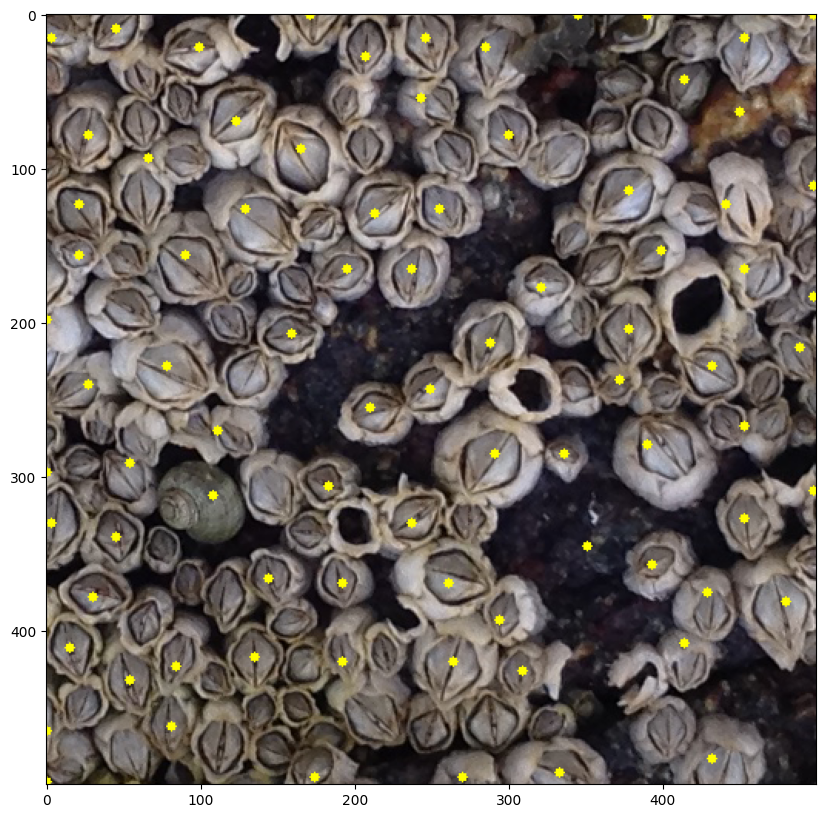

In [38]:
imgB = cv2.imread("unseen_img2.png")
grayB = cv2.cvtColor(imgB, cv2.COLOR_BGR2GRAY)
ptsB = detectOnPhoto(clfC, grayB, half=35, stride=3, thresh=0.2)
print("unseen_img2, whole image:", len(ptsB))

show = imgB.copy()                      # full size: the photo is small, so do not shrink it
for x, y in ptsB:
    cv2.circle(show, (int(x), int(y)), 3, (0, 255, 255), -1)
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(show, cv2.COLOR_BGR2RGB))
plt.savefig("unseen2_overlay.png", dpi=150, bbox_inches="tight")
plt.show()

| Photo | Region | Window | Detections |
|---|---|---|---|
| `unseen_img1` | inner square, 50 px margin | 41 px | about 990 |
| `unseen_img2` | whole image, reflected edges | 71 px | about 83 |

`unseen_img1`: the dots sit on barnacles, but a patch of bare rock in the upper-middle gets false dots. `unseen_img2`: at full size the dots sit near the centers and the doubles are gone, but several smaller barnacles on the left have no dot, and one dot sits on the snail. My hand counts say the `unseen_img1` total is plausible to about ±10%, but I couldn't check `unseen_img2` the same way.

## 10. Results, caveats, conclusions, what I learned

### Scoreboard (labeled photos)
Scored at 10 px on `img1` and 18 px on `img2` (whose barnacles are bigger), on the right half of each photo, from one run with seed 0. "Chance" is the F1 of random points in the same box with the same number of detections. "Count" is detections minus real barnacles, as a percentage of the real ones. A rerun can move the second decimal.

The numbers here and in Sections 4-8 are copied from one full Restart-and-Run-All on my own machine.

| Method | `img1` right half: F1 (chance), count | `img2`: F1 (chance), count |
|---|---|---|
| Brightness threshold | unusable | not scored |
| Template matching (threshold 0.1) | 0.43 (0.20), -6% | not tested |
| Blob detection (DoG, sigma 8) | 0.26 (0.17), -34% | not tested |
| Random forest, `img1` only (0.2 / 0.1) | 0.75 (0.20), -4% | 0.38 (0.17), +65% (whole photo, never seen) |
| Random forest, both photos (0.2) | 0.67 (0.19), -13% | 0.35 (0.11), -47% (right half) |
| Random forest, both photos (0.1) | 0.66 (0.20), -10% | 0.54 (0.18), +17% (right half) |
| Random forest, both photos, balanced negatives (0.2) | 0.71 (0.20), -3% | 0.56 (0.18), +27% (right half) |

Over five seeds, the balanced forest at threshold 0.2 scores about 0.73 +- 0.01 on `img1` and about 0.56 +- 0.01 on `img2`.

What the table says: the forest is the only method clearly above chance (3x on `img1`, about 3x on `img2`). Template matching is about 2x chance, and the blob detector is barely above it. The forest's count is within a few percent on `img1` but overcounts `img2` by roughly a quarter, partly from unlabeled real barnacles and partly from rock and wire. A correct count can come from wrong detections (DoG sigma 6 had +4.7% error at chance-level F1), so count error has to be read next to precision and recall.

### Unseen photos
Counts depend on the region and the edge handling, so see Section 9.

### Caveats
- Labels are incomplete, even in `img1`. Precision is probably understated (real but unlabeled barnacles count as false positives). Recall could be overstated if the labeled ones are the easy ones. I don't know the net effect on F1.
- I picked thresholds using the same test halves I score on, so the scores are slightly optimistic.
- The `img2` results from the both-photos classifiers are a same-photo split (left half to train, right half to test), which is easier than a new photo. The only fully unseen labeled test is `img2` with the `img1`-only classifier (F1 about 0.4).
- The `img1` and `img2` test sets are the right halves of two photos, so there are really only two scenes. I haven't tested on photos from other days or places.
- I set the hand choices (window size per photo, inset margin around the frame) by looking at pictures, not by tuning against labels.
- The unseen counts have no ground truth. The hand-count check on a few crops is the only check, and I placed the rock crop by hand, so it isn't a random sample.

### Conclusions
The random forest is the only method clearly above chance: F1 about 0.73 on `img1`'s right half (chance 0.2), about 0.56 on `img2`'s right half, and only about 0.38 on `img2` as a truly unseen photo. Its count is within a few percent on `img1` but overcounts `img2` by about 27% on its right half at threshold 0.2. On `img2` as a fully unseen photo (the `img1`-only forest), the count error swings from +65% at threshold 0.1 to +8.5% at 0.2, and the 0.2 total comes with a low F1 of 0.32, so that total depends heavily on the threshold and hides misplaced dots. The hand check suggests a pattern: it undercounts in dense clusters and overcounts on rock. That's not good enough to replace counting, but it's good enough to propose dots that a person can quickly fix, so I'd pursue a human-in-the-loop version. I'd keep the forest and the inner-square crop and drop brightness thresholding and blob detection. With more time I'd add more labeled photos, add hard negatives near centers (untested), pick the window size automatically instead of by eye, and test on photos from other days.

### What I learned
- I assumed my chance level was 0.03, and that was wrong, because my random points mostly missed the labeled area. The fair value was about 0.21, which showed blob detection was barely better than guessing.
- I expected template matching's flat precision to be a consistent shift, so I tested it. The mean offset was about 0 and the spread was 8-9 px, so it was random scatter.
- A method can get the count right with the dots in the wrong places (DoG, +4.7%), and my own hand check showed the same thing: the totals matched while individual crops were off by up to 36%.
- I first counted the whole photo, but scientists only count inside the frame.

Next time I'd build the chance baseline, the count-error reporting and a fully unseen test photo from the start.